<a href="https://colab.research.google.com/github/PriyanshuChaubey/GAN/blob/main/vanilla_gan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install torchvision

In [ ]:
!unzip "/content/drive/MyDrive/img_align_celeba.zip" -d /content/dataset

Streaming output truncated to the last 5000 lines.
 extracting: /content/dataset/img_align_celeba/197600.jpg  
 extracting: /content/dataset/img_align_celeba/197601.jpg  
 extracting: /content/dataset/img_align_celeba/197602.jpg  
 extracting: /content/dataset/img_align_celeba/197603.jpg  
 extracting: /content/dataset/img_align_celeba/197604.jpg  
 extracting: /content/dataset/img_align_celeba/197605.jpg  
 extracting: /content/dataset/img_align_celeba/197606.jpg  
 extracting: /content/dataset/img_align_celeba/197607.jpg  
 extracting: /content/dataset/img_align_celeba/197608.jpg  
 extracting: /content/dataset/img_align_celeba/197609.jpg  
 extracting: /content/dataset/img_align_celeba/197610.jpg  
 extracting: /content/dataset/img_align_celeba/197611.jpg  
 extracting: /content/dataset/img_align_celeba/197612.jpg  
 extracting: /content/dataset/img_align_celeba/197613.jpg  
 extracting: /content/dataset/img_align_celeba/197614.jpg  
 extracting: /content/dataset/img_align_celeba/19

In [ ]:
import torch
import os
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image

In [ ]:
class ImageProcessor:
  def __init__(self, root_dir_path, transformation=None):
    self.root_dir_path = root_dir_path
    self.transformations = transformation
     #list of all paths for all images
    self.all_img_paths = [os.path.join(root_dir_path, img) for img in os.listdir(root_dir_path)]

  def __len__(self):
    return len(self.all_img_paths)

  def __getitem__(self, idx):
    img_path = self.all_img_paths[idx]
    img = Image.open(img_path).convert("RGB")

    if self.transformations:
      img = self.transformations(img)

    return img

In [ ]:
root_dir_path = "/content/dataset/img_align_celeba"

transformations = transforms.Compose([
    transforms.CenterCrop(178),
    transforms.Resize(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

loaded 202599 images


In [ ]:
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

In [ ]:
import torch.nn as nn
import torch.optim as optim
import numpy as np

Generator Network

In [ ]:
class Generator(nn.Module):
  def __init__(self, z_dim=100, img_channels=3):
    super(Generator, self).__init__()

    # Fully connected layer
    self.model = nn.Sequential(
        nn.Linear(z_dim, 256),
        nn.ReLU(),

        nn.Linear(256, 512),
        nn.ReLU(),

        nn.Linear(512, 1024),
        nn.ReLU(),

        nn.Linear(1024, 64*64* img_channels),
        nn.Tanh()
    )

  def forward(self, z):
    img = self.model(z)
    img = img.view(img.size(0), 3, 64, 64)
    return img

Discriminator Network

In [ ]:
class Discriminator(nn.Module):
  def __init__(self, img_channels=3):
    super(Discriminator, self).__init__()

    # Fully connected layer
    self.model = nn.Sequential(
        nn.Flatten(),


        nn.Linear(img_channels*64*64, 1024),
        nn.ReLU(),

        nn.Linear(1024, 512),
        nn.LeakyReLU(0.2, inplace=True),

        nn.Linear(512, 256),
        nn.LeakyReLU(0.2, inplace=True),

        nn.Linear(256, 1),
        nn.Sigmoid()
    )

  def forward(self, img):
    return self.model(img)

In [ ]:
GAN_loss = nn.BCELoss()

generator = Generator()
g_optimizer = optim.Adam(generator.parameters(), lr = 0.0002, betas=(0.5, 0.999))

discriminator = Discriminator()
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))


In [ ]:
import torch

if torch.cuda.is_available():
  device = torch.device("cuda")

else:
  device = torch.device("cpu")

  print(f"device is {device}")

In [ ]:
generator = generator.to(device)
discriminator = discriminator.to(device)

In [ ]:
def train(generator, discriminator, dataloader, epochs=10):

    for epoch in range(epochs):
        for i, imgs in enumerate(dataloader):
            real_imgs = imgs.to(device)
            batch_size = real_imgs.size(0)

            # creates real imgs labels & fake imgs labels
            real_labels = torch.ones(batch_size, 1).to(device) # [1, 1, 1....]
            fake_labels = torch.zeros(batch_size, 1).to(device) # [0, 0, 0....]

            # Train the Discriminator
            d_optimizer.zero_grad()

            fake_imgs = generator(torch.randn(batch_size, 100).to(device))

            real_loss = GAN_loss(discriminator(real_imgs), real_labels)
            fake_loss = GAN_loss(discriminator(fake_imgs.detach()), fake_labels)

            d_loss = (real_loss + fake_loss) / 2

            d_loss.backward()
            d_optimizer.step()

            # Train the Generator
            g_optimizer.zero_grad()

            g_loss = GAN_loss(discriminator(fake_imgs), real_labels)

            g_loss.backward()
            g_optimizer.step()

            if i % 50 == 0:
                print(f"for epoch: {epoch+1}/{epochs}... batch: {i+1}... G-loss:{g_loss}.... D-loss: {d_loss}")

        # save generated imgs for each epoch
        save_generated_images(generator, epoch, device)

In [ ]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(generator, epoch, device, num_imgs=8):
    z = torch.randn(num_imgs, 100).to(device)
    generated_imgs = generator(z).detach().cpu()

    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=True)

    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.title(f"epoch {epoch+1}")
    plt.axis("off")
    plt.show()

for epoch: 1/8... batch: 1... G-loss:0.73287433385849.... D-loss: 0.6942809820175171
for epoch: 1/8... batch: 51... G-loss:1.1552457809448242.... D-loss: 0.22687697410583496
for epoch: 1/8... batch: 101... G-loss:0.626467764377594.... D-loss: 0.5006369948387146
for epoch: 1/8... batch: 151... G-loss:1.274844765663147.... D-loss: 0.2454148530960083
for epoch: 1/8... batch: 201... G-loss:2.212101459503174.... D-loss: 0.32248613238334656
for epoch: 1/8... batch: 251... G-loss:2.1417288780212402.... D-loss: 0.12916375696659088
for epoch: 1/8... batch: 301... G-loss:2.357348918914795.... D-loss: 0.06868021935224533
for epoch: 1/8... batch: 351... G-loss:1.978445053100586.... D-loss: 0.13433837890625
for epoch: 1/8... batch: 401... G-loss:4.072074890136719.... D-loss: 0.06260953843593597
for epoch: 1/8... batch: 451... G-loss:2.431682586669922.... D-loss: 0.122096948325634
for epoch: 1/8... batch: 501... G-loss:2.638288974761963.... D-loss: 0.293809175491333
for epoch: 1/8... batch: 551... G

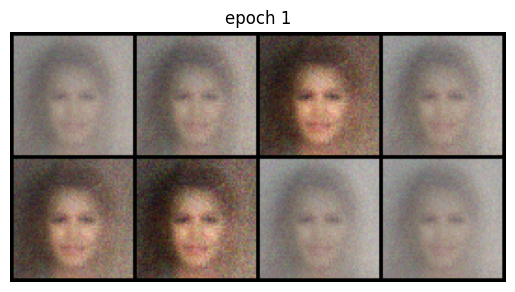

for epoch: 2/8... batch: 1... G-loss:3.1123366355895996.... D-loss: 0.08099741488695145
for epoch: 2/8... batch: 51... G-loss:3.2122669219970703.... D-loss: 0.07728464156389236
for epoch: 2/8... batch: 101... G-loss:5.1387481689453125.... D-loss: 0.10623563826084137
for epoch: 2/8... batch: 151... G-loss:2.6257388591766357.... D-loss: 0.13686755299568176
for epoch: 2/8... batch: 201... G-loss:3.761427879333496.... D-loss: 0.061723385006189346
for epoch: 2/8... batch: 251... G-loss:3.1768648624420166.... D-loss: 0.1555229127407074
for epoch: 2/8... batch: 301... G-loss:2.9580137729644775.... D-loss: 0.15987449884414673
for epoch: 2/8... batch: 351... G-loss:3.025236129760742.... D-loss: 0.09996173530817032
for epoch: 2/8... batch: 401... G-loss:4.424080848693848.... D-loss: 0.18544931709766388
for epoch: 2/8... batch: 451... G-loss:3.4820985794067383.... D-loss: 0.0513363778591156
for epoch: 2/8... batch: 501... G-loss:3.295287609100342.... D-loss: 0.08975780010223389
for epoch: 2/8... 

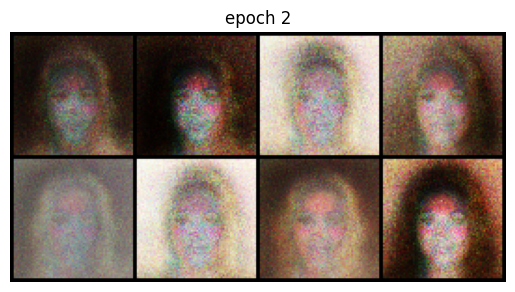

for epoch: 3/8... batch: 1... G-loss:3.671112537384033.... D-loss: 0.28106075525283813
for epoch: 3/8... batch: 51... G-loss:8.288727760314941.... D-loss: 0.7661998867988586
for epoch: 3/8... batch: 101... G-loss:2.9010019302368164.... D-loss: 0.19749073684215546
for epoch: 3/8... batch: 151... G-loss:2.782870292663574.... D-loss: 0.1971426010131836
for epoch: 3/8... batch: 201... G-loss:2.232912540435791.... D-loss: 0.32424190640449524
for epoch: 3/8... batch: 251... G-loss:3.6648130416870117.... D-loss: 0.5932825207710266
for epoch: 3/8... batch: 301... G-loss:2.4472527503967285.... D-loss: 0.28521081805229187
for epoch: 3/8... batch: 351... G-loss:3.336723566055298.... D-loss: 0.2670421600341797
for epoch: 3/8... batch: 401... G-loss:2.6567163467407227.... D-loss: 0.328546941280365
for epoch: 3/8... batch: 451... G-loss:2.5830469131469727.... D-loss: 0.31763049960136414
for epoch: 3/8... batch: 501... G-loss:3.008556365966797.... D-loss: 0.2888107895851135
for epoch: 3/8... batch: 5

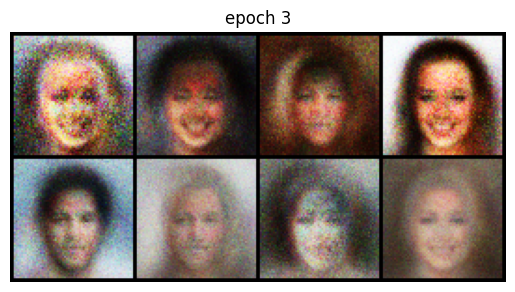

for epoch: 4/8... batch: 1... G-loss:2.1733617782592773.... D-loss: 0.4525498151779175
for epoch: 4/8... batch: 51... G-loss:2.5787453651428223.... D-loss: 0.3049236238002777
for epoch: 4/8... batch: 101... G-loss:2.742466688156128.... D-loss: 0.28312256932258606
for epoch: 4/8... batch: 151... G-loss:2.445827007293701.... D-loss: 0.30109357833862305
for epoch: 4/8... batch: 201... G-loss:2.28464937210083.... D-loss: 0.4721932113170624
for epoch: 4/8... batch: 251... G-loss:2.405956268310547.... D-loss: 0.34960228204727173
for epoch: 4/8... batch: 301... G-loss:2.035276412963867.... D-loss: 0.40103620290756226
for epoch: 4/8... batch: 351... G-loss:2.4070749282836914.... D-loss: 0.2758920192718506
for epoch: 4/8... batch: 401... G-loss:2.18194580078125.... D-loss: 0.34580275416374207
for epoch: 4/8... batch: 451... G-loss:2.3900065422058105.... D-loss: 0.31217628717422485
for epoch: 4/8... batch: 501... G-loss:1.9683926105499268.... D-loss: 0.3922685980796814
for epoch: 4/8... batch: 5

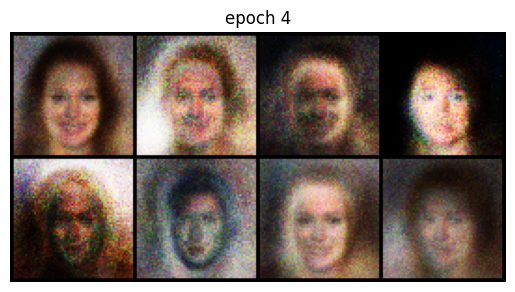

for epoch: 5/8... batch: 1... G-loss:2.2792952060699463.... D-loss: 0.37849658727645874
for epoch: 5/8... batch: 51... G-loss:2.2606449127197266.... D-loss: 0.3421279191970825
for epoch: 5/8... batch: 101... G-loss:1.928659439086914.... D-loss: 0.43929535150527954
for epoch: 5/8... batch: 151... G-loss:1.9499552249908447.... D-loss: 0.3691049814224243
for epoch: 5/8... batch: 201... G-loss:2.477692127227783.... D-loss: 0.38174381852149963
for epoch: 5/8... batch: 251... G-loss:2.0505564212799072.... D-loss: 0.39294663071632385
for epoch: 5/8... batch: 301... G-loss:2.5007948875427246.... D-loss: 0.4123019874095917
for epoch: 5/8... batch: 351... G-loss:2.1709704399108887.... D-loss: 0.32326310873031616
for epoch: 5/8... batch: 401... G-loss:2.1846790313720703.... D-loss: 0.39032477140426636
for epoch: 5/8... batch: 451... G-loss:1.932043194770813.... D-loss: 0.4382113814353943
for epoch: 5/8... batch: 501... G-loss:1.8695553541183472.... D-loss: 0.42538443207740784
for epoch: 5/8... ba

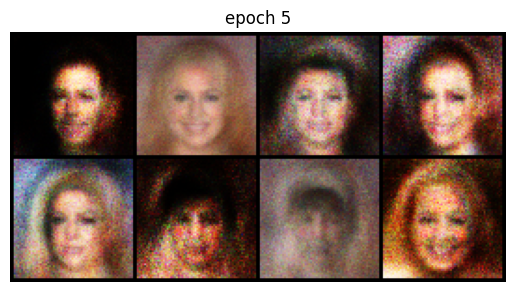

for epoch: 6/8... batch: 1... G-loss:1.9479711055755615.... D-loss: 0.4048713743686676
for epoch: 6/8... batch: 51... G-loss:1.6078381538391113.... D-loss: 0.520876944065094
for epoch: 6/8... batch: 101... G-loss:2.02716064453125.... D-loss: 0.38410794734954834
for epoch: 6/8... batch: 151... G-loss:2.0785317420959473.... D-loss: 0.3578178882598877
for epoch: 6/8... batch: 201... G-loss:1.859392762184143.... D-loss: 0.4331512451171875
for epoch: 6/8... batch: 251... G-loss:1.7922136783599854.... D-loss: 0.4005211889743805
for epoch: 6/8... batch: 301... G-loss:1.7784810066223145.... D-loss: 0.49527961015701294
for epoch: 6/8... batch: 351... G-loss:1.9952545166015625.... D-loss: 0.42597806453704834
for epoch: 6/8... batch: 401... G-loss:2.1713080406188965.... D-loss: 0.4565173089504242
for epoch: 6/8... batch: 451... G-loss:1.9275641441345215.... D-loss: 0.43924832344055176
for epoch: 6/8... batch: 501... G-loss:1.584033727645874.... D-loss: 0.4720243811607361
for epoch: 6/8... batch: 

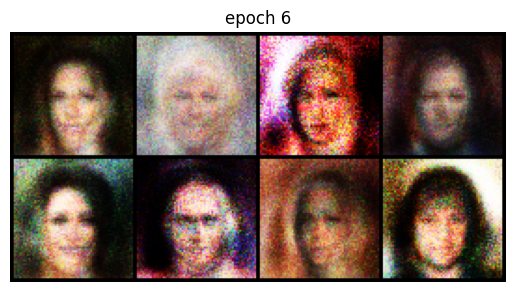

for epoch: 7/8... batch: 1... G-loss:1.5376895666122437.... D-loss: 0.4802287817001343
for epoch: 7/8... batch: 51... G-loss:1.7086262702941895.... D-loss: 0.424701988697052
for epoch: 7/8... batch: 101... G-loss:1.6500122547149658.... D-loss: 0.5066838264465332
for epoch: 7/8... batch: 151... G-loss:1.5990605354309082.... D-loss: 0.5103610157966614
for epoch: 7/8... batch: 201... G-loss:1.7088441848754883.... D-loss: 0.5291159152984619
for epoch: 7/8... batch: 251... G-loss:1.6374471187591553.... D-loss: 0.4408428370952606
for epoch: 7/8... batch: 301... G-loss:1.5751893520355225.... D-loss: 0.5612435936927795
for epoch: 7/8... batch: 351... G-loss:1.7251355648040771.... D-loss: 0.4835462272167206
for epoch: 7/8... batch: 401... G-loss:1.7923049926757812.... D-loss: 0.48263588547706604
for epoch: 7/8... batch: 451... G-loss:1.6928858757019043.... D-loss: 0.4192434251308441
for epoch: 7/8... batch: 501... G-loss:1.7598649263381958.... D-loss: 0.5918440818786621
for epoch: 7/8... batch:

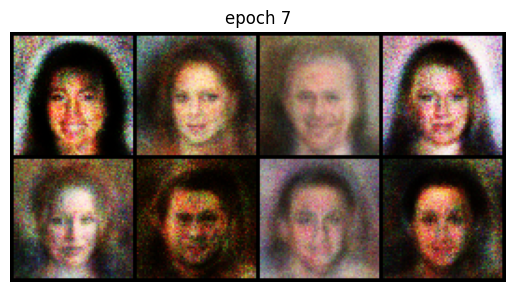

for epoch: 8/8... batch: 1... G-loss:1.6483359336853027.... D-loss: 0.53947913646698
for epoch: 8/8... batch: 51... G-loss:1.802875280380249.... D-loss: 0.5691207647323608
for epoch: 8/8... batch: 101... G-loss:1.4502686262130737.... D-loss: 0.542845606803894
for epoch: 8/8... batch: 151... G-loss:1.705552577972412.... D-loss: 0.5342344641685486
for epoch: 8/8... batch: 201... G-loss:1.5656682252883911.... D-loss: 0.5099007487297058
for epoch: 8/8... batch: 251... G-loss:1.3270807266235352.... D-loss: 0.5726727247238159
for epoch: 8/8... batch: 301... G-loss:1.2926770448684692.... D-loss: 0.5921773910522461
for epoch: 8/8... batch: 351... G-loss:1.691185712814331.... D-loss: 0.4892697334289551
for epoch: 8/8... batch: 401... G-loss:1.387502908706665.... D-loss: 0.5144343376159668
for epoch: 8/8... batch: 451... G-loss:1.601649522781372.... D-loss: 0.6110484004020691
for epoch: 8/8... batch: 501... G-loss:1.646951675415039.... D-loss: 0.48225855827331543
for epoch: 8/8... batch: 551... 

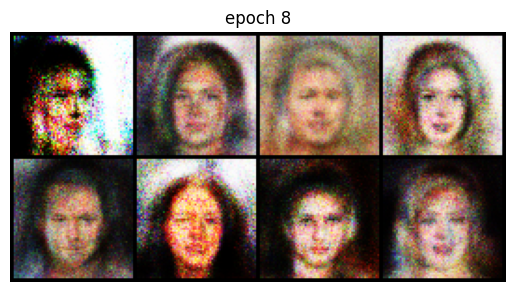

In [ ]:
train(generator, discriminator, dataloader, epochs=8)